# HKDL Six-Ride Performance Model — PortAventura reference data

**한국어 안내:** 외부 참고 공원을 PortAventura World로 통일했습니다. HKDL 6개 모두 분석합니다. 원자료를 수정하지 않습니다. 이 노트북은 데이터 분석·모형 보정·민감도 분석·그래프 생성용이며 보고서 생성 코드는 없습니다.

**Evidence boundaries:** Park names are dataset labels, not independently authenticated provenance. External operational records provide a downtime scenario; HKDL published waits are calibration targets. Dispatch headways and most vehicle/service parameters below are explicit assumptions. Model outputs are NOT measured HKDL throughput, utilization, failures, or actual guest waits. Matching waits does not uniquely identify arrival rate or capacity.

**Scope:** Baseline annual-mean calibration plus hourly representative-regime calibration for all six rides. Each hourly regime is simulated independently; these are not a continuous day's arrivals. Posted HKDL waits are treated as a proxy for experienced waits (1:1 baseline; alternative ratios tested). No balking, abandonment, priority lane split, party packing, or queue interaction across rides is modeled.

In [1]:
from pathlib import Path
import json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/external/theme_park_hackathon/waiting_times.csv.gz').exists())
RAW = ROOT/'data/external/theme_park_hackathon'
OUT = ROOT/'output/six_ride_model'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi':130, 'axes.spines.top':False, 'axes.spines.right':False})
SEED=2703
SOURCE_YEAR=2019
print('Workspace:', ROOT)
print('Python:', platform.python_version(), 'pandas:', pd.__version__, 'numpy:', np.__version__)


Workspace: <project-root>
Python: 3.11.3 pandas: 3.0.3 numpy: 2.4.6


## 1. Source selection and metric-specific cleaning

Use the provided ride-to-park mapping with a validated many-to-one join. `WAIT_TIME_MAX` is the maximum reported within a 15-minute interval, **not mean guest wait**. External waits are not scaled to become HKDL observations.

Separate reliability and throughput filters: a bad passenger count must not erase a valid outage record. Closed intervals are excluded from the open-time denominator, not treated as zero-wait service. Duplicate keys are diagnosed before use. Excess throughput is flagged rather than silently capped at capacity. The `CAPACITY` unit is under-specified in the glossary; utilization uses the explicitly time-slot-adjusted `ADJUST_CAPACITY`, and is called **adjusted-capacity ratio**, pending operational validation.

In [2]:
raw=pd.read_csv(RAW/'waiting_times.csv.gz')
links=pd.read_csv(RAW/'link_attraction_park.csv', sep=';')
assert not links.ATTRACTION.duplicated().any()
raw=raw.merge(links, left_on='ENTITY_DESCRIPTION_SHORT', right_on='ATTRACTION', how='left', validate='many_to_one')
assert raw.PARK.notna().all()
raw['date']=pd.to_datetime(raw.WORK_DATE.str.strip())
raw['start']=pd.to_datetime(raw.DEB_TIME)
raw['end']=pd.to_datetime(raw.FIN_TIME)
raw['interval_min']=(raw.end-raw.start).dt.total_seconds()/60
park_comparison=raw.groupby('PARK').agg(rows=('PARK','size'), rides=('ATTRACTION','nunique'))
display(park_comparison)
park_comparison.to_csv(OUT/'park_comparison.csv')
pa=raw.loc[raw.PARK.eq('PortAventura World')].copy()
assert pa.duplicated(['ATTRACTION','start']).sum()==0
assert pa.interval_min.eq(15).all()
reliability_ok=(pa.OPEN_TIME.between(0,15)&pa.UP_TIME.ge(0)&pa.DOWNTIME.ge(0)
                &pa.DOWNTIME.le(pa.OPEN_TIME)&np.isclose(pa.UP_TIME+pa.DOWNTIME,pa.OPEN_TIME))
flow_ok=(reliability_ok & pa.OPEN_TIME.gt(0) & pa.GUEST_CARRIED.ge(0)
         &pa.ADJUST_CAPACITY.gt(0)&pa.GUEST_CARRIED.le(pa.ADJUST_CAPACITY*1.05))
checks=pd.Series({'raw_all_parks':len(raw),'portaventura_rows':len(pa),
 'duplicate_ride_timestamp':int(pa.duplicated(['ATTRACTION','start']).sum()),
 'invalid_time_rows':int((~reliability_ok).sum()),
 'negative_guest_rows':int(pa.GUEST_CARRIED.lt(0).sum()),
 'closed_rows':int(pa.OPEN_TIME.eq(0).sum()),
 'guests_above_adjusted_capacity_plus_5pct':int((pa.ADJUST_CAPACITY.gt(0)&pa.GUEST_CARRIED.gt(pa.ADJUST_CAPACITY*1.05)).sum()),
 'retained_flow_rows':int(flow_ok.sum())},name='rows')
display(checks.to_frame()); checks.to_csv(OUT/'quality_checks.csv')
flow=pa.loc[flow_ok]
external=flow.groupby('ATTRACTION').agg(rows=('ATTRACTION','size'),guests=('GUEST_CARRIED','sum'),open_min=('OPEN_TIME','sum'),adjusted_capacity=('ADJUST_CAPACITY','sum'))
external['flow_per_open_hour']=external.guests/(external.open_min/60)
external['adjusted_capacity_ratio']=external.guests/external.adjusted_capacity
rel=pa.loc[reliability_ok&pa.OPEN_TIME.gt(0)].groupby('ATTRACTION').agg(down_min=('DOWNTIME','sum'),open_min=('OPEN_TIME','sum'))
external['downtime_pct']=100*rel.down_min/rel.open_min
external.to_csv(OUT/'external_ride_summary.csv')
display(external[['rows','flow_per_open_hour','adjusted_capacity_ratio','downtime_pct']].round(3))
del raw


,rows,rides
PARK,,
PortAventura World,2369821,26
Tivoli Gardens,1139503,13


,rows
raw_all_parks,3509324
portaventura_rows,2369821
duplicate_ride_timestamp,0
invalid_time_rows,65
negative_guest_rows,209
closed_rows,1080609
guests_above_adjusted_capacity_plus_5pct,9937
retained_flow_rows,1242095


,rows,flow_per_open_hour,adjusted_capacity_ratio,downtime_pct
ATTRACTION,,,,
Bumper Cars,54896,622.734,0.615,0.834
Bungee Jump,54247,814.489,0.738,5.243
Circus Train,52494,789.050,0.564,1.134
Crazy Dance,54057,412.673,0.416,3.487
Dizzy Dropper,58853,401.891,0.481,1.858
Drop Tower,54504,363.333,0.657,2.137
Flying Coaster,57201,1534.320,0.548,6.312
Free Fall,46653,176.861,0.431,0.514
Giant Wheel,58408,918.746,0.522,9.693


## 2. Empirical downtime blocks from one external park

Base year: 2019, before COVID operational changes. Use complete 15-minute open intervals with valid time accounting. Build **contiguous one-hour blocks from a single ride and date**; do not concatenate gaps, closed periods or different rides. Resample these blocks, retaining within-hour dependence. Between-hour dependence and overnight effects are not preserved. Pooled blocks weight recorded valid operating hours, not rides equally.

The source records minutes down but not the exact outage start. Within each quarter-hour, position the observed downtime interval uniformly at random. This is an assumption, not a recovered failure event. No mechanical-failure cause is inferred. The same empirical distribution is used for all six HKDL models to avoid claiming six unsupported reliability measurements.

84,101 contiguous one-hour blocks; reference downtime: 3.513%
This is external downtime, NOT HKDL downtime.


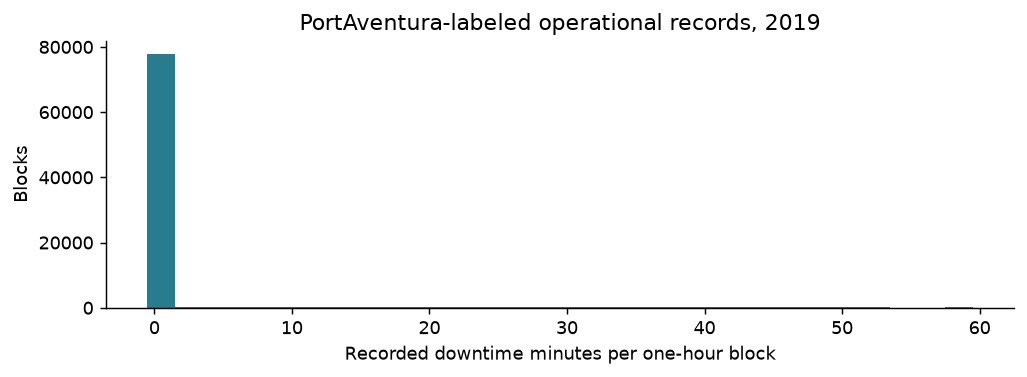

In [3]:
base=pa.loc[reliability_ok & pa.OPEN_TIME.eq(15) & pa.date.dt.year.eq(SOURCE_YEAR)].sort_values(['ATTRACTION','start'])
blocks=[]
for (ride,date),g in base.groupby(['ATTRACTION','date'],sort=False):
    # Non-overlapping complete clock-hour blocks.
    for hour,h in g.groupby(g.start.dt.hour):
        if len(h)==4 and h.start.dt.minute.tolist()==[0,15,30,45]:
            blocks.append(h.DOWNTIME.to_numpy(dtype=float))
blocks=np.asarray(blocks)
assert blocks.shape[1]==4 and len(blocks)>100
np.save(OUT/'portaventura_2019_downtime_blocks.npy',blocks)
source_down=float(blocks.mean()/15)
print(f'{len(blocks):,} contiguous one-hour blocks; reference downtime: {source_down:.3%}')
print('This is external downtime, NOT HKDL downtime.')
fig,ax=plt.subplots(figsize=(8,3))
ax.hist(blocks.sum(axis=1),bins=np.arange(-.5,61.5,2),color='#287c8e')
ax.set(xlabel='Recorded downtime minutes per one-hour block',ylabel='Blocks',title='PortAventura-labeled operational records, 2019')
fig.tight_layout();fig.savefig(OUT/'external_downtime.png');plt.show()


## 3. HKDL targets, published specifications and explicit assumptions

2025 HKDL Queue-Times posted-wait summaries are calibration targets, not actual guest timings. Annual and hourly summaries are different aggregates; do not force their averages to coincide.

**New source audit (20 October 2026):** HKDL's official accessibility guide lists trip times of 7, 1, 6, 4, 5 and 4 minutes for Frozen, RC Racer, Mystic Manor, Hyperspace Mountain, Iron Man and Ant-Man. These published trip times replace duration assumptions. They are not departure headways or complete load/unload cycles. The guide is used consistently even where databases report shorter ride durations (e.g. RCDB lists 2:30 for Hyperspace). Their timing boundaries may differ; the chosen values are visitor-facing approximate trip times, not dispatch observations.

Hyperspace's prior 24-seat assumption is corrected to RCDB's 12 riders per train. RC Racer's 20 and Iron Man's 45 seats retain official sources. Frozen's 16 and Mystic Manor's maximum 6 seats are supported by first-hand published reports, not operator certifications. Ant-Man's two seats remain a model assumption. Mystic's individual-carriage service is an aggregate approximation; the report describes four-carriage dispatch groups, which this model does not explicitly reproduce.

Frozen's reference capacity is set to approximately 2,000 guests/hour from a first-hand media-preview report, replacing the previous 1,600 assumption. This is a reported capacity estimate, not measured hourly output. The model uses 2,000 exactly for computation and derives h=60*16/2000=0.48 minutes; it is not an observed departure interval. All other headways remain scenario assumptions, including Hyperspace's unchanged 1 minute, which gives 720 guests/hour with the corrected 12 seats. Do not preserve the old capacity by inventing a shorter headway.

Sources:
- [Official HKDL guide, PDF pages 7–9 / printed pages 9–14](https://secure.cdn1.wdpromedia.com/media/hkdl/guest-services/Guide-Book-Disabilities-2023-ENG.pdf)
- [RCDB: HKDL Hyperspace Mountain](https://rcdb.com/1975.htm)
- [Attractions Magazine: first-hand HKDL World of Frozen preview, 19 Nov 2023](https://attractionsmagazine.com/guide-world-of-frozen-hong-kong-disneyland/)
- [Dejiki: first-hand Mystic Manor boarding-area report](https://dejiki.com/2013/12/hkdl-mystic-manor-queue-preshow/)
- [Official RC Racer](https://www.hongkongdisneyland.com/en-hk/attractions/rc-racer/)
- [HKDL/AIA Iron Man release, p. 2](https://www.aia.com.hk/content/dam/hk/en/pdf/press-release/2016/161107-hkdl-imx-reveal-press-release-e.pdf.coredownload.pdf)

Capacity C0=B*60/h is potential output; flow rate is actual or simulated boardings per hour. Actual utilization and downtime require operating logs. Published specifications do not supply those logs. Simulation is retained for conditional scenario comparison, not because it is a mandatory assignment requirement. Big Grizzly Mountain is outside the selected six and its specifications are not transferred to them.

Guest flow time is estimated queue wait plus published trip time; unmeasured preshow/loading/transfer time is not separately added. No claim is made that this is an exact end-to-end guest measurement.


In [4]:
public=json.loads((ROOT/'output/performance_assessment/public_data_2025.json').read_text())
params=pd.DataFrame({
 'ride':public['names'], 'batch_size':[16,20,6,12,45,2],
 'headway_min':[0.48,4.0,0.4,1.0,2.5,0.1],
 'ride_duration_min':[7.0,1.0,6.0,4.0,5.0,4.0],
 'batch_evidence':['first-hand preview report','official seat count','first-hand boarding report','RCDB published train capacity','official seat count','scenario assumption'],
 'headway_evidence':['derived from approximate published capacity']+['scenario assumption']*5,
 'duration_evidence':['official HKDL guide trip time']*6,
 'posted_wait_target_min':public['annual'],
 'wait_source':[f'https://queue-times.com/parks/31/rides/{rid}/2025' for rid in public['ids']]
})
params['duration_source']='https://secure.cdn1.wdpromedia.com/media/hkdl/guest-services/Guide-Book-Disabilities-2023-ENG.pdf'
params['capacity_evidence']=['approximate media-preview estimate']+['calculated from assumed headway']*5
params['nominal_capacity_ph']=params.batch_size*60/params.headway_min
params.to_csv(OUT/'model_inputs.csv',index=False)
display(params.drop(columns='wait_source'))


,ride,batch_size,headway_min,ride_duration_min,batch_evidence,headway_evidence,duration_evidence,posted_wait_target_min,duration_source,capacity_evidence,nominal_capacity_ph
0,Frozen Ever After,16,0.48,7.0,first-hand preview report,derived from approximate published capacity,official HKDL guide trip time,31,https://secure.cdn1.wdpromedia.com/media/hkdl/...,approximate media-preview estimate,2000.0
1,RC Racer,20,4.00,1.0,official seat count,scenario assumption,official HKDL guide trip time,31,https://secure.cdn1.wdpromedia.com/media/hkdl/...,calculated from assumed headway,300.0
2,Mystic Manor,6,0.40,6.0,first-hand boarding report,scenario assumption,official HKDL guide trip time,22,https://secure.cdn1.wdpromedia.com/media/hkdl/...,calculated from assumed headway,900.0
3,Hyperspace Mountain,12,1.00,4.0,RCDB published train capacity,scenario assumption,official HKDL guide trip time,16,https://secure.cdn1.wdpromedia.com/media/hkdl/...,calculated from assumed headway,720.0
4,Iron Man Experience,45,2.50,5.0,official seat count,scenario assumption,official HKDL guide trip time,12,https://secure.cdn1.wdpromedia.com/media/hkdl/...,calculated from assumed headway,1080.0
5,Ant-Man and The Wasp,2,0.10,4.0,scenario assumption,scenario assumption,official HKDL guide trip time,9,https://secure.cdn1.wdpromedia.com/media/hkdl/...,calculated from assumed headway,1200.0


## 4. Batch-service FIFO simulator

Poisson guest arrivals; fixed dispatch headway; a dispatch is cancelled if its scheduled instant falls inside a sampled downtime interval. Each available dispatch boards up to the assumed batch capacity. Unfilled seats are lost, not carried forward. No guests are removed for long waits. After the observation period, arrivals stop and the queue drains; incomplete drainage raises an error rather than dropping long waits.

Queue recursion at departure j: `Q_j=max(0,Q_(j-1)+A_j-B)`. A reflected cumulative-sum implementation is equivalent to this recursion. Each guest's boarding time is recovered from cumulative boardings. Warmup guests create backlog but are excluded from wait statistics. Flow rate uses boardings during the observation window, whereas waits use guests arriving in that window. Both utilization denominators are reported.

Calibration and evaluation use different random seeds. Confidence intervals describe **Monte Carlo uncertainty conditional on assumptions**, not confidence in the true HKDL parameters. The simulation runs continuously for a long representative operating regime; it is not a literal multi-day park schedule.

In [5]:
def boarding_times(arrivals, departures, batch):
    arrived=np.searchsorted(arrivals,departures,side='right')
    net=arrived-batch*np.arange(1,len(departures)+1)
    queue=net-np.minimum.accumulate(np.r_[0,net])[1:]
    served=arrived-queue
    ix=np.searchsorted(served,np.arange(1,len(arrivals)+1),side='left')
    if len(ix) and ix.max()>=len(departures):
        raise RuntimeError('Queue did not drain; extend drain time.')
    return departures[ix],served

def simulate(row,arrival_ph,seed,warm_min=2880,observe_min=10080,down_scale=1.0,capacity_scale=1.0):
    rng=np.random.default_rng(seed)
    stop=warm_min+observe_min
    end=stop+2880  # no arrivals in this drain interval
    n_blocks=int(np.ceil(end/60))
    down=blocks[rng.integers(len(blocks),size=n_blocks)].ravel()
    down=np.minimum(15,down*down_scale)
    starts=np.arange(len(down))*15+rng.random(len(down))*(15-down)
    headway=float(row.headway_min)/capacity_scale
    dep=np.arange(headway,end,headway)
    dep=dep[dep < end-1e-9]  # guard floating-point endpoint inclusion
    slot=np.floor(dep/15).astype(int)
    active=~((dep>=starts[slot])&(dep<starts[slot]+down[slot]))
    dep=dep[active]
    # Exponential interarrivals give a Poisson process. A separate seeded stream
    # preserves common random numbers and monotonic arrivals during rate calibration.
    arng=np.random.default_rng(seed+1000000)
    expected=arrival_ph*stop/60
    count_bound=int(expected+15*np.sqrt(expected)+1000)
    candidates=np.cumsum(arng.exponential(size=count_bound))*60/arrival_ph
    assert candidates[-1]>stop
    arrivals=candidates[candidates<stop]
    count=len(arrivals)
    boarded,served=boarding_times(arrivals,dep,int(row.batch_size))
    cohort=arrivals>=warm_min
    waits=boarded[cohort]-arrivals[cohort]
    board_count=int(((boarded>=warm_min)&(boarded<stop)).sum())
    seats=int(((dep>=warm_min)&(dep<stop)).sum())*int(row.batch_size)
    down_minutes=np.maximum(0,np.minimum(starts+down,stop)-np.maximum(starts,warm_min)).sum()
    q_end=count-int(np.searchsorted(boarded,stop,side='left'))
    assert waits.min()>=-1e-8 and np.all(np.diff(boarded)>=0)
    nominal=float(row.nominal_capacity_ph)*capacity_scale
    return {'wait_min':waits.mean(),'p95_wait_min':np.quantile(waits,.95),
       'flow_ph':board_count/(observe_min/60),'available_capacity_ph':seats/(observe_min/60),
       'util_nominal_pct':100*board_count/(nominal*observe_min/60),
       'util_available_pct':100*board_count/seats,
       'downtime_pct':100*down_minutes/observe_min,
       'queue_at_end':q_end,'arrivals_observation':int(cohort.sum())}

# Independent check of the vectorized FIFO algorithm against a small explicit case.
a=np.array([.1,.2,.3,1.1,3.1]);d=np.arange(1.,7.)
b,s=boarding_times(a,d,2)
assert np.array_equal(b,np.array([1.,1.,2.,2.,4.]))
assert s[-1]==len(a)
print('FIFO, conservation, and drain check passed.')


FIFO, conservation, and drain check passed.


## 5. Calibrate all six annual targets

Only arrival rate is adjusted while capacity and downtime assumptions remain fixed. A bisection fit matches the mean over calibration replications. Upper bound = 99.95% of nominal capacity × mean external availability; this keeps the intended long-run load below available capacity. If a target cannot be bracketed, it is flagged as unmatched, not silently claimed as fitted.

Because the target is posted wait, the baseline assumes posted and experienced means coincide. This assumption is tested later. These estimates are one feasible parameterization, not uniquely recovered demand.

In [6]:
CAL_SEEDS=list(range(27030,27046))
EVAL_SEEDS=list(range(80000,80032))
wait_cache={}
def mean_wait(row,rate,seeds=CAL_SEEDS):
    key=(row.ride,float(rate),tuple(seeds))
    if key not in wait_cache:
        wait_cache[key]=float(np.mean([simulate(row,rate,s)['wait_min'] for s in seeds]))
    return wait_cache[key]

def calibrate(row,target,seeds=CAL_SEEDS,steps=13):
    lo=float(row.nominal_capacity_ph)*.05
    hi=float(row.nominal_capacity_ph)*(1-source_down)*.9995
    wl=mean_wait(row,lo,seeds);wh=mean_wait(row,hi,seeds)
    if not wl<=target<=wh:
        rate=lo if target<wl else hi
        return rate,mean_wait(row,rate,seeds),False
    for _ in range(steps):
        mid=(lo+hi)/2
        if mean_wait(row,mid,seeds)<target:lo=mid
        else:hi=mid
    rate=(lo+hi)/2
    fit=mean_wait(row,rate,seeds)
    return rate,fit,abs(fit-target)<=1.0

fit_rows=[]
for row in params.itertuples(index=False):
    rate,fit,ok=calibrate(row,row.posted_wait_target_min)
    fit_rows.append({'ride':row.ride,'arrival_ph':rate,'fit_wait_min':fit,'fit_ok':ok,
                     'target_min':row.posted_wait_target_min})
    print(row.ride,round(rate,1),'guests/h; target',row.posted_wait_target_min,'fit',round(fit,2),'matched',ok,flush=True)
fits=pd.DataFrame(fit_rows)
fits.to_csv(OUT/'annual_calibration.csv',index=False)


Frozen Ever After 1884.2 guests/h; target 31 fit 31.0 matched True


RC Racer 280.7 guests/h; target 31 fit 31.1 matched True


Mystic Manor 835.3 guests/h; target 22 fit 21.98 matched True


Hyperspace Mountain 658.0 guests/h; target 16 fit 16.0 matched True


Iron Man Experience 966.9 guests/h; target 12 fit 11.99 matched True


Ant-Man and The Wasp 1063.2 guests/h; target 9 fit 9.01 matched True


## 6. Independent-seed evaluation and sensitivity

Report held-out seed means and Monte Carlo 95% intervals. A seed split evaluates numerical robustness, **not external validation against HKDL flow data**. Scenarios hold fitted arrivals fixed: capacity +10%, downtime duration ×0.5, and arrivals +10%. Longer warmup tests transient sensitivity. Wait-target ×0.8 is separately recalibrated to test the posted/experienced-wait assumption. A capacity reduction may cause demand to exceed capacity; do not interpret such a regime as stationary.

In [7]:
records=[]
scenarios={'Baseline':{},'Capacity +10%':{'capacity_scale':1.1},'Downtime duration -50%':{'down_scale':.5},'Demand +10%':{'arrival_multiplier':1.1},'Double warmup':{'warm_min':5760}}
for row in params.itertuples(index=False):
    rate=float(fits.loc[fits.ride.eq(row.ride),'arrival_ph'].iloc[0])
    for scenario,kwargs in scenarios.items():
        opts=kwargs.copy();r=rate*opts.pop('arrival_multiplier',1)
        for seed in EVAL_SEEDS:
            value=simulate(row,r,seed,**opts)
            records.append({'ride':row.ride,'scenario':scenario,'seed':seed,'arrival_ph':r,**value})
runs=pd.DataFrame(records)
runs.to_csv(OUT/'simulation_replications.csv',index=False)
metrics=['wait_min','p95_wait_min','flow_ph','available_capacity_ph','util_nominal_pct','util_available_pct','downtime_pct','queue_at_end']
summary=runs.groupby(['ride','scenario'])[metrics].mean().reset_index()
errors=runs.groupby(['ride','scenario']).wait_min.agg(['std','count']).reset_index()
summary=summary.merge(errors,on=['ride','scenario'])
summary['wait_mc95_halfwidth']=t.ppf(.975,summary['count']-1)*summary['std']/np.sqrt(summary['count'])
summary.to_csv(OUT/'scenario_summary.csv',index=False)
result=summary[summary.scenario.eq('Baseline')].merge(params[['ride','ride_duration_min','nominal_capacity_ph','posted_wait_target_min']],on='ride').merge(fits[['ride','arrival_ph','fit_wait_min','fit_ok']],on='ride')
result['time_in_system_min']=result.wait_min+result.ride_duration_min
result['evaluation_error_min']=result.wait_min-result.posted_wait_target_min
result=result.set_index('ride').reindex(public['names']).reset_index()
result.to_csv(OUT/'six_ride_results.csv',index=False)
display(result[['ride','posted_wait_target_min','fit_wait_min','wait_min','wait_mc95_halfwidth','flow_ph','util_nominal_pct','util_available_pct','downtime_pct','time_in_system_min']].round(2))
assert result.ride.nunique()==6
assert runs.util_available_pct.between(0,100+1e-8).all()


,ride,posted_wait_target_min,fit_wait_min,wait_min,wait_mc95_halfwidth,flow_ph,util_nominal_pct,util_available_pct,downtime_pct,time_in_system_min
0,Frozen Ever After,31,31.00,23.33,7.31,1883.70,94.19,97.24,3.13,30.33
1,RC Racer,31,31.10,23.29,6.07,280.60,93.53,96.57,3.13,24.29
2,Mystic Manor,22,21.98,16.05,4.96,834.98,92.78,95.78,3.13,22.05
3,Hyperspace Mountain,16,16.00,12.65,3.45,658.02,91.39,94.35,3.13,16.65
4,Iron Man Experience,12,11.99,9.99,2.25,966.74,89.51,92.39,3.13,14.99
5,Ant-Man and The Wasp,9,9.01,8.00,1.96,1062.93,88.58,91.45,3.13,12.00


## 7. Hour-of-day target calibration (independent operating regimes)

Each of the 60 targets is fitted separately with the same ride-specific service model. This provides implied demand by representative hour; it is **not** a simulated continuous daily queue trajectory and must not be joined into one as if backlog carried over. Annual and hourly fits are separate. Sixteen calibration replications are used per target; annual results also use thirty-two held-out evaluation runs. Each replication has 48 operating hours of warmup and 168 observed operating hours, with no overnight closure; these are representative regimes rather than actual calendar days.

In [8]:
hour_rows=[]
for i,row in enumerate(params.itertuples(index=False)):
    for hour,target in zip(public['hours'],public['hourly'][i]):
        rate,fit,ok=calibrate(row,target,seeds=CAL_SEEDS,steps=12)
        hour_rows.append({'ride':row.ride,'hour':hour,'posted_target_min':target,'implied_arrival_ph':rate,'fit_wait_min':fit,'fit_ok':ok})
    print('Hourly regimes completed:',row.ride,flush=True)
hourly=pd.DataFrame(hour_rows)
hourly.to_csv(OUT/'hourly_regime_calibration.csv',index=False)
# Alternate posted/experienced wait ratio: all six, not a single ride.
alt=[]
for row in params.itertuples(index=False):
    rate,fit,ok=calibrate(row,.8*row.posted_wait_target_min,seeds=CAL_SEEDS,steps=12)
    alt.append({'ride':row.ride,'experienced_to_posted_ratio':.8,'target_min':.8*row.posted_wait_target_min,'arrival_ph':rate,'fit_wait_min':fit,'fit_ok':ok})
pd.DataFrame(alt).to_csv(OUT/'wait_proxy_sensitivity.csv',index=False)


Hourly regimes completed: Frozen Ever After


Hourly regimes completed: RC Racer


Hourly regimes completed: Mystic Manor


Hourly regimes completed: Hyperspace Mountain


Hourly regimes completed: Iron Man Experience


Hourly regimes completed: Ant-Man and The Wasp


## 8. Figures and interpretation checks

All graph labels distinguish published targets from model estimates. Throughput comparisons depend on assumed capacities and should not be presented as a measured ranking. A good calibration score alone is not evidence of correct throughput. Demand stress can produce growing queues; the finite-horizon output remains useful as a stress test but is not a steady-state prediction.

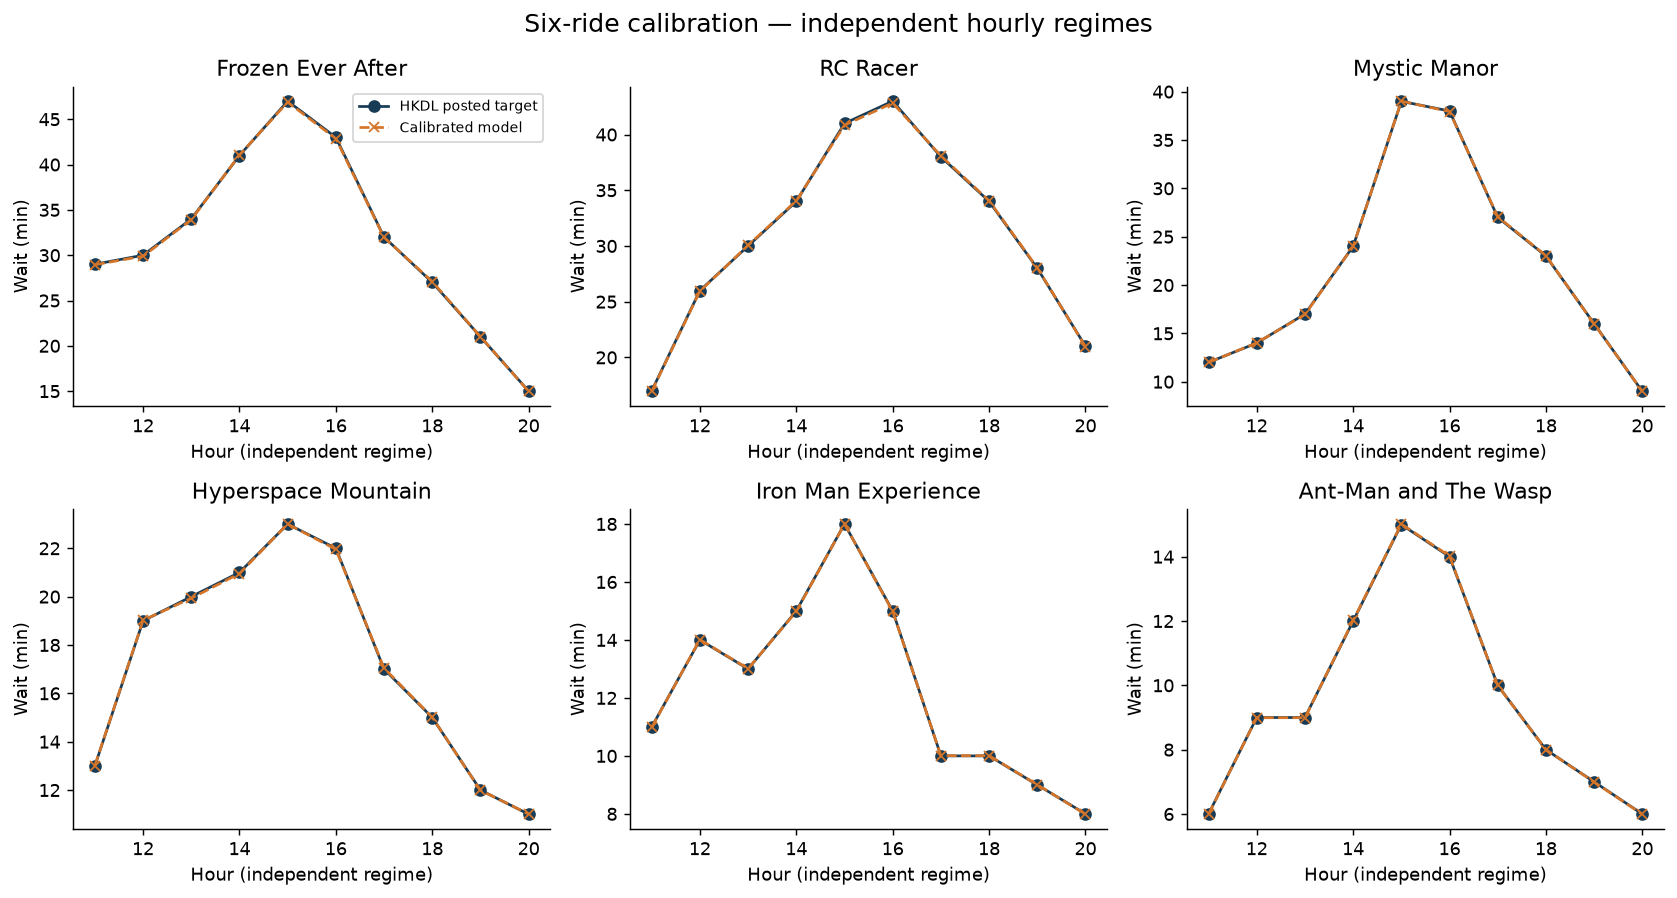

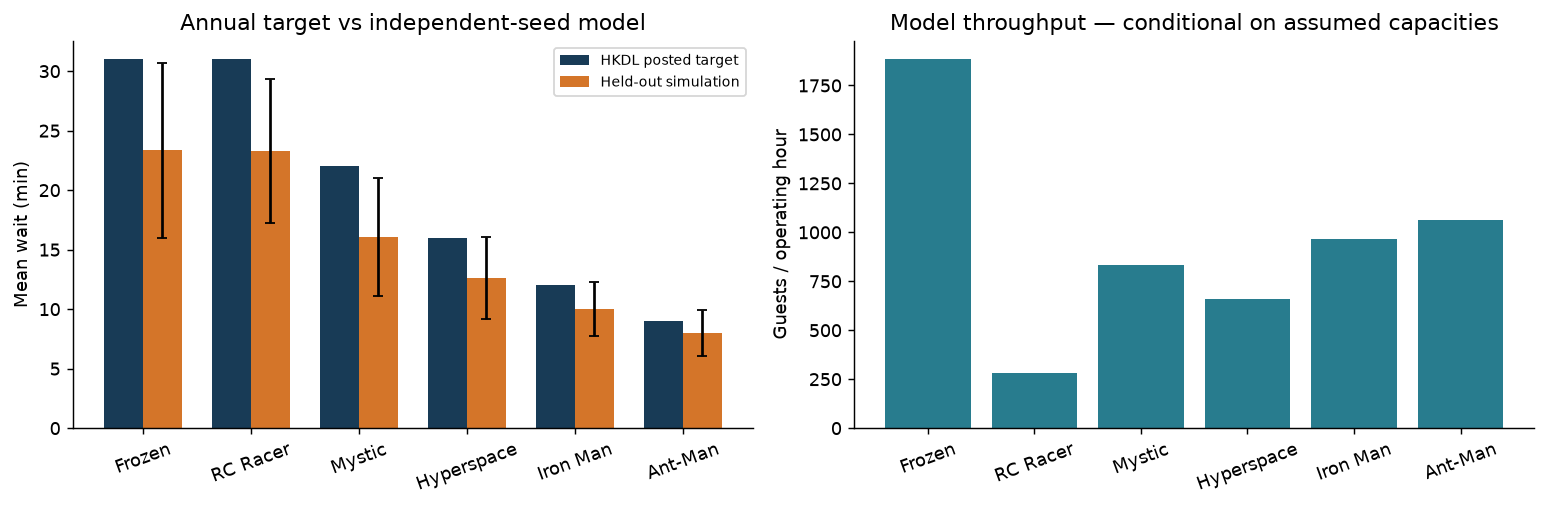

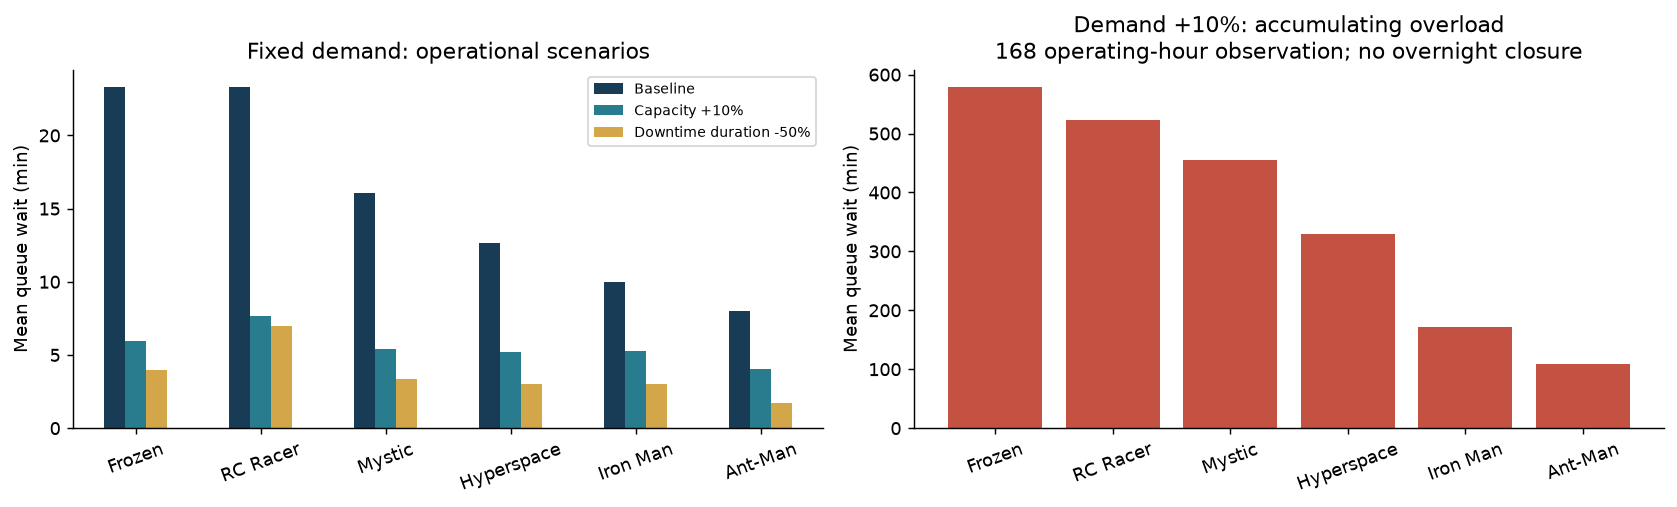

,warmup_change_min,review_transient_sensitivity
ride,,
Ant-Man and The Wasp,0.69,False
Frozen Ever After,1.23,False
Hyperspace Mountain,0.56,False
Iron Man Experience,0.79,False
Mystic Manor,0.89,False
RC Racer,0.94,False


Annual fits within 1 min: 6 / 6
Hourly fits within 1 min: 60 / 60
Unmatched targets and material warmup differences must be disclosed; do not report them as validated results.


,ride,posted_wait_target_min,wait_min,evaluation_error_min,wait_mc95_halfwidth,within_2min_of_target
0,Frozen Ever After,31,23.33,-7.67,7.31,False
1,RC Racer,31,23.29,-7.71,6.07,False
2,Mystic Manor,22,16.05,-5.95,4.96,False
3,Hyperspace Mountain,16,12.65,-3.35,3.45,False
4,Iron Man Experience,12,9.99,-2.01,2.25,False
5,Ant-Man and The Wasp,9,8.00,-1.00,1.96,True


Calibration is not independent validation. Review seed uncertainty before using point estimates in the report.


In [9]:
fig,axes=plt.subplots(2,3,figsize=(13,7))
for ax,(i,row) in zip(axes.ravel(),params.iterrows()):
    h=hourly[hourly.ride.eq(row.ride)]
    ax.plot(h.hour,h.posted_target_min,'o-',label='HKDL posted target',color='#183b56')
    ax.plot(h.hour,h.fit_wait_min,'x--',label='Calibrated model',color='#d47529')
    ax.set(title=row.ride,xlabel='Hour (independent regime)',ylabel='Wait (min)')
axes[0,0].legend(fontsize=8)
fig.suptitle('Six-ride calibration — independent hourly regimes',fontsize=14)
fig.tight_layout();fig.savefig(OUT/'hourly_calibration.png');plt.show()

fig,axes=plt.subplots(1,2,figsize=(12,4))
x=np.arange(6);labels=['Frozen','RC Racer','Mystic','Hyperspace','Iron Man','Ant-Man']
axes[0].bar(x-.18,result.posted_wait_target_min,.36,label='HKDL posted target',color='#183b56')
axes[0].bar(x+.18,result.wait_min,.36,yerr=result.wait_mc95_halfwidth,label='Held-out simulation',color='#d47529',capsize=3)
axes[0].set(ylabel='Mean wait (min)',title='Annual target vs independent-seed model')
axes[0].legend(fontsize=8)
axes[1].bar(x,result.flow_ph,color='#287c8e')
axes[1].set(ylabel='Guests / operating hour',title='Model throughput — conditional on assumed capacities')
for ax in axes:ax.set_xticks(x,labels,rotation=20)
fig.tight_layout();fig.savefig(OUT/'baseline_results.png');plt.show()

fig,axes=plt.subplots(1,2,figsize=(13,4))
pivot=summary[summary.scenario.isin(['Baseline','Capacity +10%','Downtime duration -50%'])].pivot(index='ride',columns='scenario',values='wait_min').reindex(public['names'])
pivot.index=labels
pivot.plot.bar(ax=axes[0],color=['#183b56','#287c8e','#d4a64a'])
axes[0].set(ylabel='Mean queue wait (min)',xlabel='',title='Fixed demand: operational scenarios')
stress=summary[summary.scenario.eq('Demand +10%')].set_index('ride').reindex(public['names'])
axes[1].bar(labels,stress.wait_min,color='#c35243')
axes[1].set(ylabel='Mean queue wait (min)',title='Demand +10%: accumulating overload\n168 operating-hour observation; no overnight closure')
for ax in axes: ax.tick_params(axis='x',rotation=20)
axes[0].legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT/'sensitivity.png');plt.show()

warm=summary.pivot(index='ride',columns='scenario',values='wait_min')
checks=pd.DataFrame({'warmup_change_min':warm['Double warmup']-warm.Baseline})
checks['review_transient_sensitivity']=checks.warmup_change_min.abs()>2
checks.to_csv(OUT/'warmup_check.csv')
display(checks.round(2))
print('Annual fits within 1 min:', int(fits.fit_ok.sum()),'/ 6')
print('Hourly fits within 1 min:', int(hourly.fit_ok.sum()),'/ 60')
print('Unmatched targets and material warmup differences must be disclosed; do not report them as validated results.')

validation=result[['ride','posted_wait_target_min','wait_min','evaluation_error_min','wait_mc95_halfwidth']].copy()
validation['within_2min_of_target']=validation.evaluation_error_min.abs()<=2
validation.to_csv(OUT/'independent_seed_check.csv',index=False)
display(validation.round(2))
print('Calibration is not independent validation. Review seed uncertainty before using point estimates in the report.')


## 9. What can be used in the report / 보고서에 사용할 범위

- **Published specifications:** six official trip times; official or third-party seating references; approximate Frozen capacity from a first-hand media preview. Published capacity is not observed throughput.
- **Observed:** HKDL posted-wait targets; external 2019 operational records and their audited summaries.
- **Assumed:** five service headways, Ant-Man batch size, aggregate carriage dispatch, Poisson arrivals, pooled transfer of downtime, placement within 15-minute bins, and 1:1 posted/experienced-wait relationship.
- **Calibrated:** arrival rates under those assumptions.
- **Simulated:** throughput, queue waits, capacity utilization, time in system, and downtime outcomes.
- **Limitation:** individual arrivals, dispatch logs, HKDL actual throughput and reliability are not available. Source reliability blocks are not a passenger arrival distribution. Do not derive Poisson rates from park-wide annual attendance divided among rides.

한국어: 6개 모형이 모두 실행되더라도 실제 홍콩 운영값을 복원한 것은 아닙니다. 가정을 고정했을 때 대기시간과 일치하는 도착률을 찾고, 같은 수요에서 처리능력·중단시간 개선의 영향을 비교하는 분석입니다. 이용률은 명목 처리능력 기준과 중단을 반영한 가용 처리능력 기준을 구분하세요. 중단율은 외부 자료를 이전한 입력이므로 홍콩의 고장률이라고 쓰지 마세요. 실제 개선 제안은 안전 절차 단축을 전제하지 않습니다.

Next refinement: verify remaining headways, batch-service simplifications and published capacity estimates, model actual opening/closing and the six within-day arrival curves jointly, add separate priority/standby flows if supporting data becomes available, and validate on independent HKDL observations if obtained.